# MDM AIML Assignment: Ensemble Learning Techniques

**Aim:** To implement Stacking, AdaBoost and Voting ensemble classifiers, compare them with individual base classifiers, and evaluate their performance using classification metrics.

**Dataset:** Wine Recognition dataset from Scikit-learn. It contains 178 samples, 13 numerical features and 3 target classes.

## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

## 2. Load and Explore the Dataset

In [2]:
data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset: Wine Recognition")
print("Total samples:", X.shape[0])
print("Total features:", X.shape[1])
print("Target classes:", data.target_names)
display(X.head())

print("\\nClass distribution:")
print(y.value_counts().sort_index().rename(
    index={i: name for i, name in enumerate(data.target_names)}
))

Dataset: Wine Recognition
Total samples: 178
Total features: 13
Target classes: ['class_0' 'class_1' 'class_2']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


\nClass distribution:
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


## 3. Split the Dataset

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 142
Testing samples: 36


## 4. Define Base Classifiers

In [4]:
def create_base_models():
    return {
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=5000)
        ),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "KNN": make_pipeline(
            StandardScaler(), KNeighborsClassifier(n_neighbors=5)
        ),
        "SVM": make_pipeline(
            StandardScaler(),
            SVC(kernel="linear", probability=True, random_state=42)
        )
    }

base_models = create_base_models()

## 5. Define the Evaluation Function

In [5]:
results = []
all_predictions = {}
all_models = {}

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision (Macro)": precision,
        "Recall (Macro)": recall,
        "F1 Score (Macro)": f1
    })

    all_predictions[name] = y_pred
    all_models[name] = model

    print("=" * 60)
    print("MODEL:", name)
    print("=" * 60)
    print("Accuracy:", round(accuracy, 4))
    print("Precision (Macro):", round(precision, 4))
    print("Recall (Macro):", round(recall, 4))
    print("F1 Score (Macro):", round(f1, 4))
    print("\\nClassification Report:")
    print(classification_report(
        y_test, y_pred, target_names=data.target_names, zero_division=0
    ))

    return y_pred

## 6. Train and Evaluate Individual Base Classifiers

In [6]:
for name, model in base_models.items():
    model.fit(X_train, y_train)
    evaluate_model(name, model, X_test, y_test)

MODEL: Logistic Regression
Accuracy: 0.9722
Precision (Macro): 0.9778
Recall (Macro): 0.9667
F1 Score (Macro): 0.971
\nClassification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

MODEL: Decision Tree
Accuracy: 0.9444
Precision (Macro): 0.9583
Recall (Macro): 0.9389
F1 Score (Macro): 0.9457
\nClassification Report:
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg  

## 7. Implement Stacking Ensemble

In [ ]:
stacking_estimators = [
    ("lr", make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000)
    )),
    ("dt", DecisionTreeClassifier(random_state=42)),
    ("knn", make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    )),
    ("svm", make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", probability=True, random_state=42)
    ))
]

meta_classifier = LogisticRegression(max_iter=5000)
 
stacking_model = StackingClassifier(
    estimators=stacking_estimators,
    final_estimator=meta_classifier,
    cv=5,
    stack_method="predict_proba"
)

stacking_model.fit(X_train, y_train)
evaluate_model("Stacking Classifier", stacking_model, X_test, y_test)

MODEL: Stacking Classifier
Accuracy: 0.9722
Precision (Macro): 0.9778
Recall (Macro): 0.9667
F1 Score (Macro): 0.971
\nClassification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



array([0, 1, 0, 1, 1, 0, 0, 1, 1, 2, 1, 2, 0, 2, 0, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 2, 1, 2, 0, 2, 1, 2, 2, 2])

## 8. Implement AdaBoost Ensemble

In [8]:
weak_learner = DecisionTreeClassifier(max_depth=1, random_state=42)

adaboost_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(X_train, y_train)
evaluate_model("AdaBoost Classifier", adaboost_model, X_test, y_test)

MODEL: AdaBoost Classifier
Accuracy: 0.9167
Precision (Macro): 0.9267
Recall (Macro): 0.919
F1 Score (Macro): 0.9198
\nClassification Report:
              precision    recall  f1-score   support

     class_0       0.86      1.00      0.92        12
     class_1       0.92      0.86      0.89        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.92        36
   macro avg       0.93      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



array([0, 2, 0, 0, 1, 0, 0, 0, 1, 2, 1, 2, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 2, 1, 2, 0, 2, 1, 2, 2, 2])

## 9. Implement Voting Ensemble

In [9]:
voting_estimators = [
    ("lr", make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=5000)
    )),
    ("dt", DecisionTreeClassifier(random_state=42)),
    ("knn", make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    )),
    ("svm", make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", probability=True, random_state=42)
    ))
]

voting_model = VotingClassifier(
    estimators=voting_estimators,
    voting="hard"
)

voting_model.fit(X_train, y_train)
evaluate_model("Voting Classifier", voting_model, X_test, y_test)

MODEL: Voting Classifier
Accuracy: 0.9722
Precision (Macro): 0.9778
Recall (Macro): 0.9667
F1 Score (Macro): 0.971
\nClassification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



array([0, 1, 0, 1, 1, 0, 0, 1, 1, 2, 1, 2, 0, 2, 0, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 1, 0, 2, 1, 2, 0, 2, 1, 2, 2, 2])

## 10. Performance Comparison

In [10]:
results_df = pd.DataFrame(results)

display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (Macro)": "{:.4f}",
    "Recall (Macro)": "{:.4f}",
    "F1 Score (Macro)": "{:.4f}"
}))

results_df.to_csv("wine_ensemble_performance_comparison.csv", index=False)
print("Performance comparison saved to wine_ensemble_performance_comparison.csv")

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,Logistic Regression,0.9722,0.9778,0.9667,0.9710
1,Decision Tree,0.9444,0.9583,0.9389,0.9457
2,KNN,0.9722,0.9697,0.9762,0.9718
3,SVM,0.9444,0.9505,0.9429,0.9453
4,Stacking Classifier,0.9722,0.9778,0.9667,0.9710
5,AdaBoost Classifier,0.9167,0.9267,0.9190,0.9198
6,Voting Classifier,0.9722,0.9778,0.9667,0.9710


Performance comparison saved to wine_ensemble_performance_comparison.csv


## 11. Visualize Performance Metrics

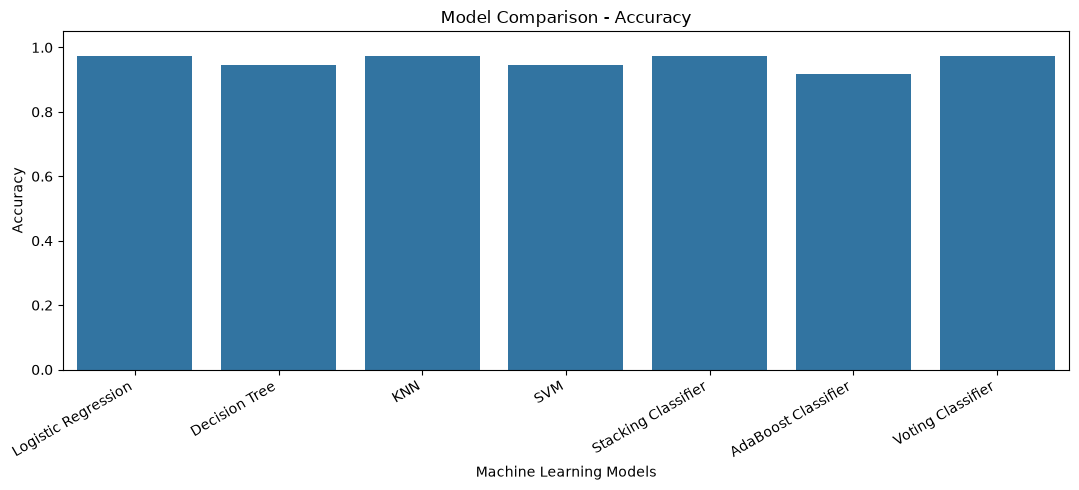

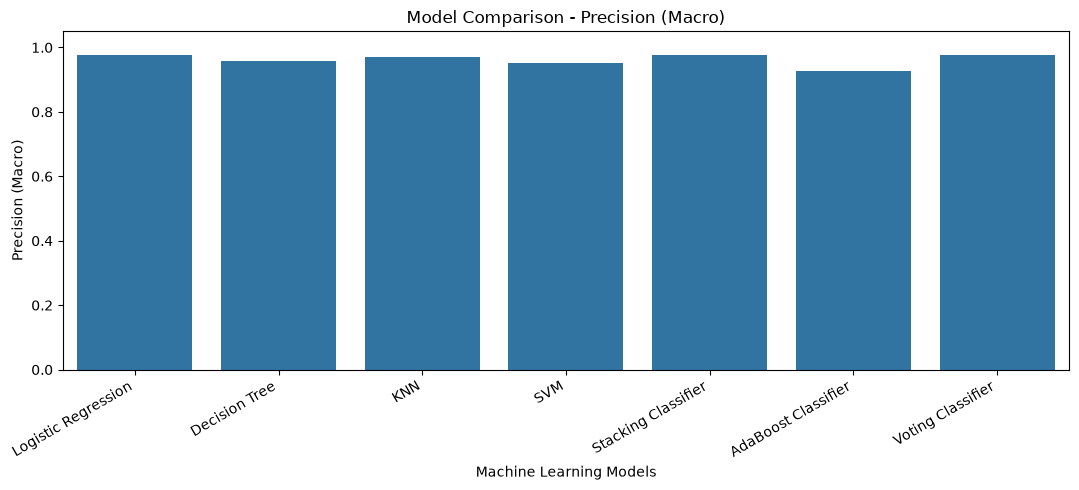

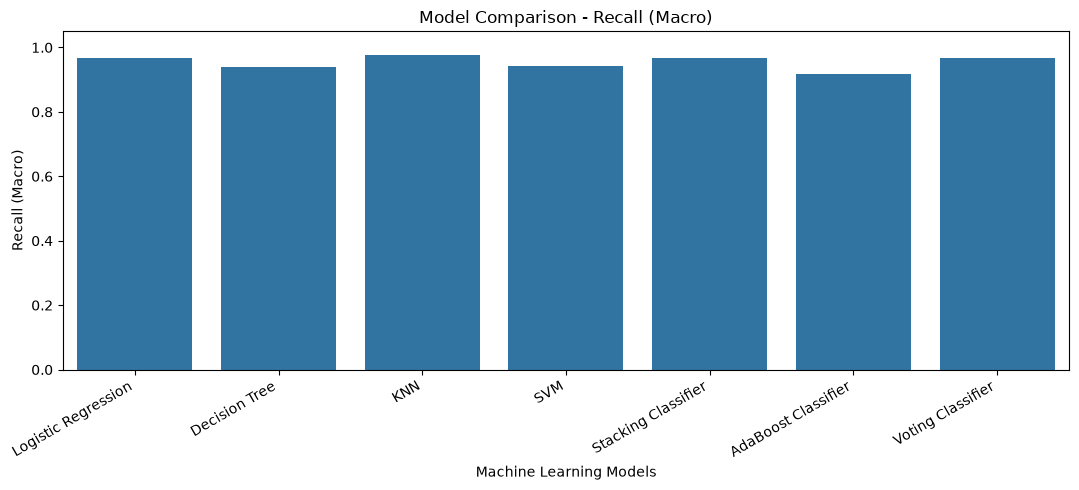

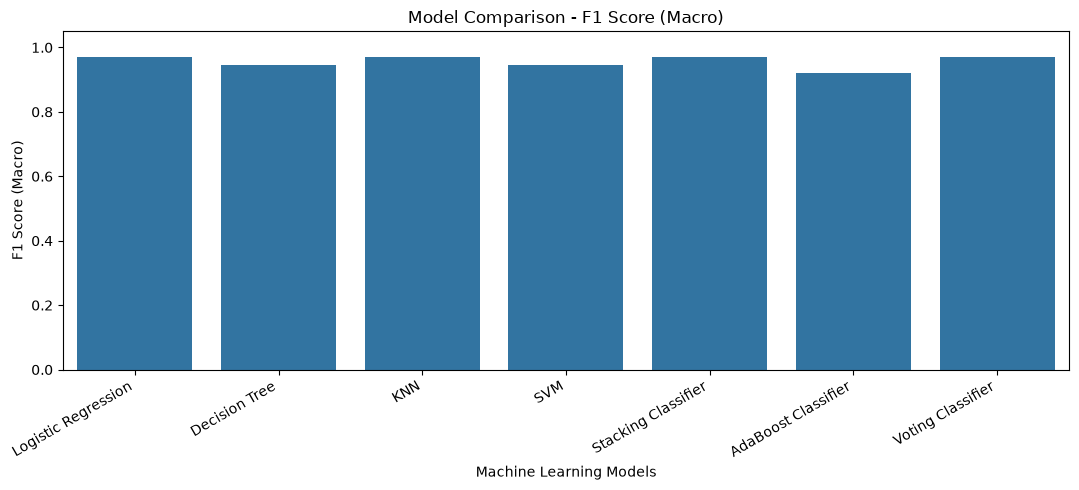

In [11]:
metrics = [
    "Accuracy", "Precision (Macro)", "Recall (Macro)", "F1 Score (Macro)"
]

for metric in metrics:
    plt.figure(figsize=(11, 5))
    sns.barplot(data=results_df, x="Model", y=metric)
    plt.title("Model Comparison - " + metric)
    plt.xlabel("Machine Learning Models")
    plt.ylabel(metric)
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

## 12. Confusion Matrices for All Seven Models

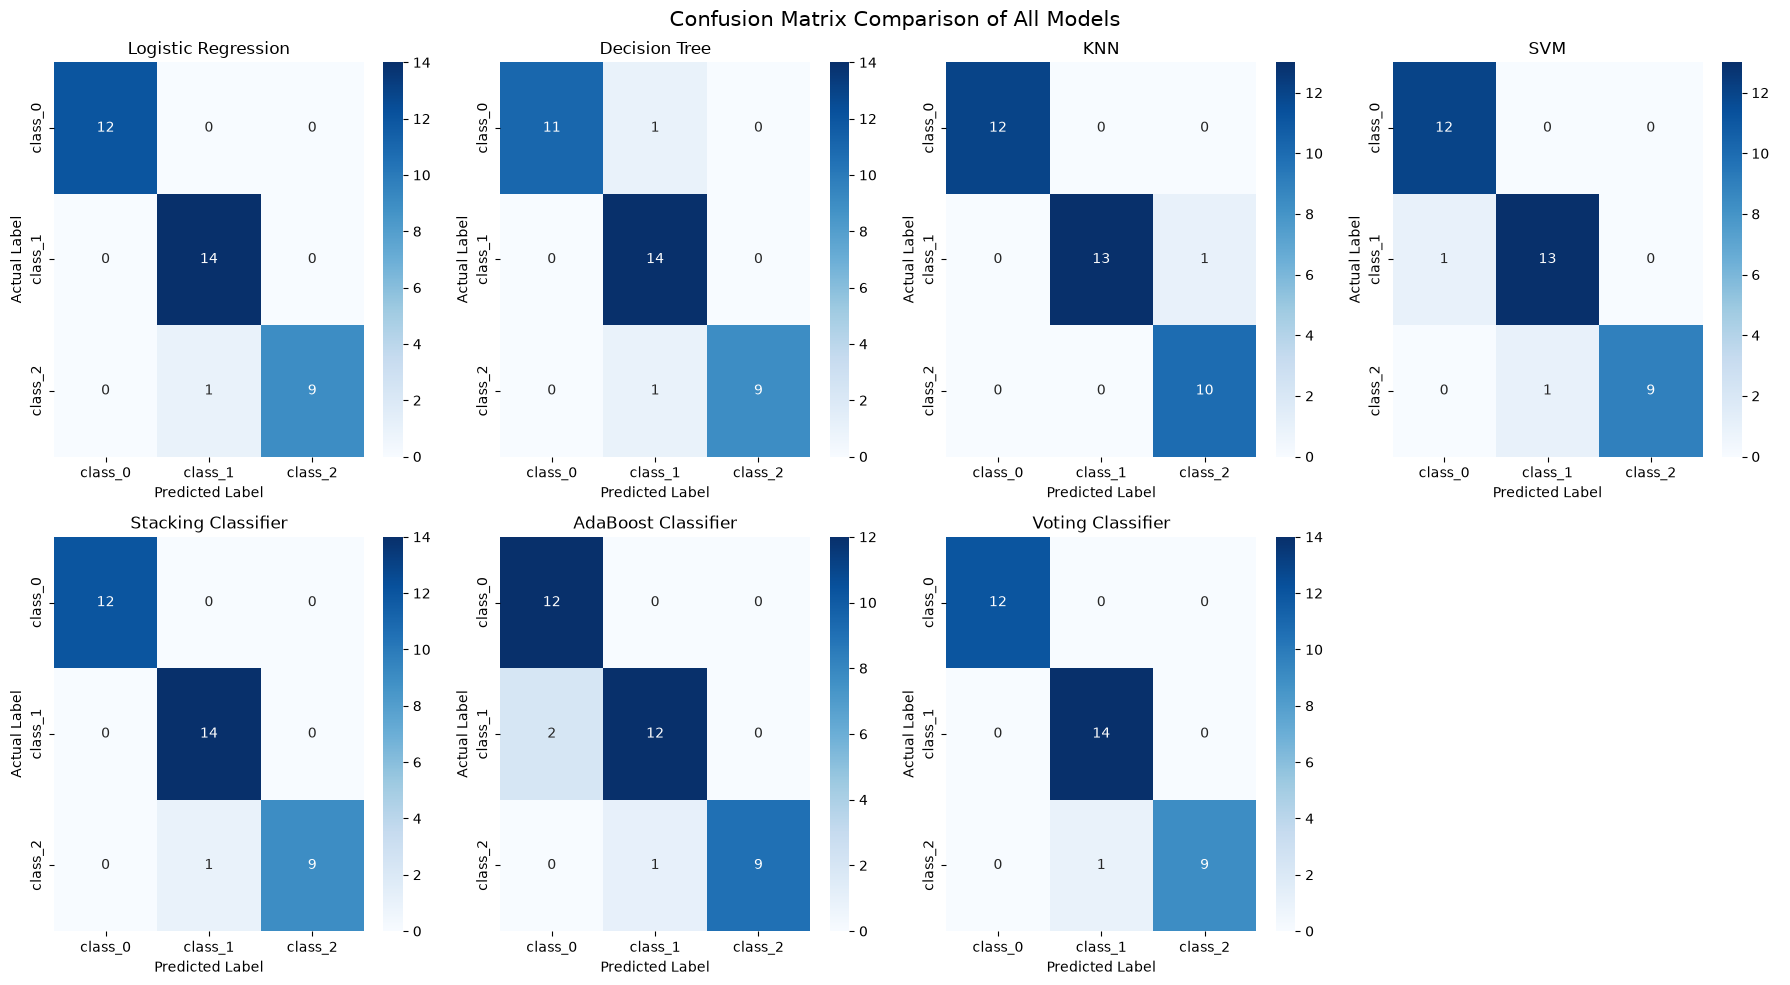

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(all_predictions.items()):
    cm = confusion_matrix(
        y_test, y_pred, labels=np.arange(len(data.target_names))
    )

    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=data.target_names,
        yticklabels=data.target_names,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

axes[7].axis("off")
plt.suptitle("Confusion Matrix Comparison of All Models", fontsize=15)
plt.tight_layout()
plt.show()

## 13. Identify the Best Performing Model

In [13]:
best_model = results_df.loc[
    results_df["F1 Score (Macro)"].idxmax()
]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision (Macro):", round(best_model["Precision (Macro)"], 4))
print("Recall (Macro):", round(best_model["Recall (Macro)"], 4))
print("F1 Score (Macro):", round(best_model["F1 Score (Macro)"], 4))

Best Model: KNN
Accuracy: 0.9722
Precision (Macro): 0.9697
Recall (Macro): 0.9762
F1 Score (Macro): 0.9718


## 14. Findings and Observations

1. The Wine Recognition dataset contains three target classes, making this a multiclass classification problem.
2. Individual classifiers may produce different classification results on the same dataset.
3. Stacking combines predictions from multiple base classifiers using a meta-classifier.
4. AdaBoost trains weak learners sequentially and gives greater emphasis to previously misclassified samples.
5. Voting combines predictions from multiple classifiers using majority voting.
6. Macro-averaged precision, recall and F1 score give equal importance to each target class.
7. An ensemble model does not always outperform every individual classifier; performance depends on the dataset, model selection and parameter settings.

## 15. When to Use Each Ensemble Technique

| Ensemble technique | Suitable situation |
|---|---|
| Stacking | When diverse base classifiers are available and a meta-classifier can learn how to combine their predictions. |
| AdaBoost | When simple weak learners can be improved by focusing successively on difficult training examples. |
| Voting | When several reasonably strong and complementary classifiers are available and a straightforward combination is desired. |

## 16. Future Scope

1. Experiment with different base classifiers and meta-classifiers.
2. Apply hyperparameter tuning using GridSearchCV or RandomizedSearchCV.
3. Compare additional ensemble techniques such as Random Forest and Gradient Boosting.
4. Evaluate models using additional metrics such as macro ROC-AUC.
5. Test the models on larger and more diverse datasets.
6. Compare hard voting with soft voting.

## 17. Conclusion

The experiment implements and evaluates three ensemble learning techniques: Stacking, AdaBoost and Voting Classifiers using the Wine Recognition dataset. Four individual base classifiers are also trained to provide a comparison.

All models are evaluated using accuracy, macro-averaged precision, recall and F1 score, along with confusion matrices. The results help illustrate how ensemble techniques combine multiple classifiers and how their performance varies with the dataset and model configuration.

The best-performing model is identified using the macro F1 score. The experiment demonstrates that ensemble learning can be useful for multiclass classification, although no ensemble method is guaranteed to outperform every individual classifier.